# sub-05: can bad signal explain the preference for the amblyopic eye?

sub-05 (sm, right esotropia, ΔlogMAR 0.70) is the only amblyope with a consistent preference for the **amblyopic** eye (V2-LO2; V1 neutral). The eye labels are supported by the source data (`od_eye_label_check.ipynb`, `sourcedata`). Remaining question: is the reversal **real**, or produced by the quality of the signal?

| section | question | if bad signal / artefact |
|---|---|---|
| A. Reproducibility | same sign in the two independent halves of the runs (3 splits)? | sign changes between halves |
| B. Noise level | is the OD of sub-05 larger than the OD obtained with crossed eye labels (pure noise)? | within the noise spread |
| C. pRF R² | does the reversal hold in the vertices with the best pRF fits? | reversal only in low-R² vertices, gone at high R² |
| D. Eccentricity | where in the visual field is the reversal? | — (descriptive: strabismic central suppression is foveal) |
| E. Individual runs | is it driven by one run (e.g. the AE Bars01 run, R² 0.05)? | disappears when one run is removed |
| F. Session order | sub-05's amblyopic eye was scanned **first**: could a decrease of the signal over the session create a fake AE advantage? | first-block advantage in the controls of the same size |
| G. Head motion | more motion in the FE runs? | FE runs with higher framewise displacement |
| H. pRFs of each eye | fit quality, vertices, eccentricity and size of each eye vs the other amblyopes | — |

Every measure is computed for **all subjects**: sub-05 is compared with the other amblyopes and with the controls. Same vertices, weights and OD index as v9 (cells copied). Read only; figures in `Desktop/fig_od` (prefix `sub05_`).

## Setup (cells copied from v9)

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = analysis_info['subjects']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

In [3]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def wcorr(x, y, w):
    """Weighted rank correlation: Pearson correlation of the ranks of x and y, each vertex weighted by w."""
    x, y, w = stats.rankdata(x), stats.rankdata(y), np.asarray(w, float)
    if np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None):
    """Median and 25-75 percentiles per group and ROI; stars = within-group test of s (FDR)."""
    patterns = patterns or [''] * len(values)
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        top = {group: -np.inf for group in groups}
        for value, pattern in zip(values, patterns):
            med, p25, p75 = [], [], []
            for group in groups:
                v = d[d.group == group][value].dropna()
                med.append(v.median()); p25.append(np.nanpercentile(v, 25)); p75.append(np.nanpercentile(v, 75))
                top[group] = max(top[group], np.nanpercentile(v, 75), v.median(), 0)
            med, p25, p75 = np.array(med), np.array(p25), np.array(p75)
            fig.add_trace(go.Bar(x=[group_labels[g] for g in groups], y=med, offsetgroup=value,
                                 marker=dict(color=[roi_colors_rgb[roi], ctrl_color],
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=p75 - med, arrayminus=med - p25, visible=True,
                                              thickness=2, width=0, color='rgba(0,0,0,1)'),
                                 showlegend=False),
                          row=1, col=col_idx)
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        for x_pos, group in enumerate(groups):
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=x_pos, y=top[group] + y_step / 2, xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0)
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(barmode='group', bargap=0.3, bargroupgap=0.05, height=fig_height, width=fig_width,
                      template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)


def wpearson(x, y, w):
    """Weighted Pearson correlation (= correlation of a weighted linear regression)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if np.sum(w) == 0 or len(x) < 3:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def deming(x, y, w=None):
    """Weighted Deming (orthogonal) regression, as in make_corr_tsv.py: returns slope, intercept.
    Symmetric in x and y (both halves are measured with noise), weights normalised to sum 1."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    x, y, w = x[ok], y[ok], w[ok]
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan, np.nan
    w = w / np.sum(w)
    mx, my = np.sum(w * x), np.sum(w * y)
    sxx, syy, sxy = np.sum(w * (x - mx) ** 2), np.sum(w * (y - my) ** 2), np.sum(w * (x - mx) * (y - my))
    if sxy == 0:
        return np.nan, np.nan
    slope = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
    return slope, my - slope * mx


def wmedian(x, w):
    """Weighted median: first value where the cumulative weight reaches half of the total."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok])
    cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def od_index(b_fe, b_ae):
    """OD index (FE - AE) / (FE + AE); defined for positive betas only."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)

In [4]:
# ---------- local cache of the vertex data (vertices of the 8 ROIs only)
vcache_dir = '{}/od_vertex_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)
deriv_keys = ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']


def subject_files(subject):
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    for eye in eyes.values():
        for kind in ['deriv', 'stats']:
            fns += [file_spec.format(pp_dir, subject, subject, task, eye, hemi, kind) for hemi in ['L', 'R']]
    return fns


def load_subject(subject):
    """Vertex data of one subject: betas, pRF parameters and fit p-value of each eye, ROI masks (full-length arrays).
    Read from the local cache when it is newer than all the source files, otherwise from the data disks (then cached)."""
    fns = subject_files(subject)
    if not all(os.path.isfile(fn) for fn in fns):
        return None
    cache_fn = '{}/{}_od-vertex-cache.npz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(fn) for fn in fns)
    if not (os.path.isfile(cache_fn) and float(np.load(cache_fn)['src_mtime']) >= src_mtime):
        od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
        rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        idx = np.where(np.any([rois[roi] for roi in rois_to_keep], axis=0))[0]
        save = {'n_vertices': od_mat.shape[1], 'idx': idx, 'src_mtime': src_mtime,
                'beta_L': od_mat[maps_names_css_od.index('od_beta_le')][idx].astype(np.float32),
                'beta_R': od_mat[maps_names_css_od.index('od_beta_re')][idx].astype(np.float32)}
        for roi in rois_to_keep:
            save['roi_{}'.format(roi)] = rois[roi][idx]
        for e, eye in eyes.items():
            deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                          R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
            st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                       R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
            for key in deriv_keys:
                save['{}_{}'.format(e, key)] = deriv[maps_names_css.index(key)][idx].astype(np.float32)
            save['{}_p'.format(e)] = st[maps_names_css_stats.index(p_name)][idx].astype(np.float32)
        np.savez_compressed(cache_fn, **save)
        print('{}: read from the data disks, cached'.format(subject), end=' | ')
    c = np.load(cache_fn)
    n, idx = int(c['n_vertices']), c['idx']

    def full(x, fill=np.nan):
        out = np.full(n, fill, dtype=float if fill is not False else bool)
        out[idx] = x
        return out
    return {'beta': {e: full(c['beta_{}'.format(e)]) for e in eyes},
            'd': {e: {key: full(c['{}_{}'.format(e, key)]) for key in deriv_keys} for e in eyes},
            'p': {e: full(c['{}_p'.format(e)]) for e in eyes},
            'rois': {roi: full(c['roi_{}'.format(roi)], False) for roi in rois_to_keep}}


def select(d, p):
    """prf_analysis filters of one eye + positive pRF amplitude (p = p-value of the pRF fit)."""
    with np.errstate(invalid='ignore'):
        return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
                & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
                & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
                & (d['prf_rsq'] >= rsqr_th)
                & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
                & (p <= stats_th))


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


rows, vertex_data = [], {}
for subject in subjects:
    group = 'patient' if subject in patients else 'control'
    sd = load_subject(subject)
    if sd is None:
        print('{}: OD image or pRF files missing, skipped'.format(subject))
        continue
    beta = sd['beta']
    keep_eye = {e: select(sd['d'][e], sd['p'][e]) & np.isfinite(beta[e]) for e in eyes}
    rsq_eye = {e: sd['d'][e]['prf_rsq'] for e in eyes}
    weight = np.nan_to_num(np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None))   # mean pRF R² of both eyes

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    keep = keep_eye['L'] & keep_eye['R']                            # pRF filters on both eyes, all betas kept
    vertex_data[subject] = {'fe': fe, 'keep': keep, 'w': weight}

    rois = sd['rois']
    for roi in rois_to_keep:
        mask = rois[roi] & keep
        w = weight[mask]
        if mask.sum() < 10 or np.sum(w) == 0:
            continue
        mask_fe, mask_ae = rois[roi] & keep_eye[fe], rois[roi] & keep_eye[ae]
        rows.append({'subject': subject, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     # vertices with beta <= 0 (kept in Figure 1, excluded from the vertex OD index)
                     'neg_any_pct': 100 * np.mean((b_fe[mask] <= 0) | (b_ae[mask] <= 0)),
                     'neg_any_w_pct': 100 * np.sum(w * ((b_fe[mask] <= 0) | (b_ae[mask] <= 0))) / np.sum(w),
                     'neg_fe_only_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] > 0)),
                     'neg_ae_only_pct': 100 * np.mean((b_ae[mask] <= 0) & (b_fe[mask] > 0)),
                     'neg_both_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] <= 0)),
                     # measures
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'od_index': wmedian(od_index(b_fe[mask], b_ae[mask]), w),     # weighted median of the vertex OD index (both β > 0)
                     # vertex-selection checks
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], weight[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], weight[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}: done'.format(subject))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done


n_vertices         pref_FE-LE         od_index        
group    control patient    control patient  control patient
roi                                                         
V1        5107.0  4320.5     51.398  57.927    0.009   0.037
V2        4681.5  4117.5     56.214  62.645    0.021   0.090
V3        3202.5  2960.0     56.632  69.918    0.030   0.145
V4        2646.0  2454.5     57.800  71.459    0.038   0.118
V3A        762.5  1000.5     53.220  70.811    0.006   0.147
V3B        305.0   509.0     46.095  83.305   -0.014   0.113
LO1        485.5   429.0     56.755  78.412    0.018   0.141
LO2        457.0   292.0     72.801  71.382    0.107   0.128

## Per-run data and helpers

Per-run GLM sums from `od_glm_common_analysis.ipynb` (run order: Bars01, Bars02, Rings, Wedges). β of an eye from any subset of its runs = Σ sxy / Σ sxx (common regressor, as v9). OD of a ROI = weighted median of the vertex OD index (both β > 0), weight = mean pRF R² (as Figure 2).

In [5]:
import itertools, glob
import matplotlib.pyplot as plt

target = 'sub-05'
run_names = ['Bars01', 'Bars02', 'Rings', 'Wedges']
all_runs = [0, 1, 2, 3]
early, late = ['V1', 'V2', 'V3'], ['V4', 'V3A', 'V3B', 'LO1', 'LO2']
roi_sets = {'V1': ['V1'], 'V2-V3': ['V2', 'V3'], 'V4-LO2': late}


def load_runs(subject):
    fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if not os.path.isfile(fn) or subject not in vertex_data:
        return None
    c = np.load(fn)
    vd = vertex_data[subject]
    vert = c['vertex']
    fe_i, ae_i = (1, 0) if vd['fe'] == 'R' else (0, 1)                 # cache eye order: 0 = left, 1 = right
    sd = load_subject(subject)                                           # local vertex cache (pRF parameters)
    fe, ae = vd['fe'], ('L' if vd['fe'] == 'R' else 'R')
    with np.errstate(divide='ignore', invalid='ignore'):
        r2 = c['sxy_own'] ** 2 / (c['sxx_own'] * c['syy'])
    sxy = {'fe': c['sxy_common'][fe_i], 'ae': c['sxy_common'][ae_i]}
    ok = np.isfinite(sxy['fe']).all(0) & np.isfinite(sxy['ae']).all(0) & np.isfinite(c['sxx_common']).all(0)
    return {'sxy': sxy, 'sxx': c['sxx_common'], 'r2_run': {'fe': r2[fe_i], 'ae': r2[ae_i]},
            'keep': vd['keep'][vert] & ok, 'w': vd['w'][vert], 'roi': c['roi'], 'fe': fe,
            'rsq': {'fe': sd['d'][fe]['prf_rsq'][vert], 'ae': sd['d'][ae]['prf_rsq'][vert]},
            'ecc': {'fe': sd['d'][fe]['prf_ecc'][vert], 'ae': sd['d'][ae]['prf_ecc'][vert]},
            'size': {'fe': sd['d'][fe]['prf_size'][vert], 'ae': sd['d'][ae]['prf_size'][vert]},
            'group': 'patient' if subject in patients else 'control'}


def beta(R, eye, runs):
    runs = list(runs)
    with np.errstate(divide='ignore', invalid='ignore'):
        return R['sxy'][eye][runs].sum(0) / R['sxx'][runs].sum(0)


def roi_mask(R, rois, extra=None):
    m = R['keep'] & np.isin(R['roi'], rois)
    return m if extra is None else m & extra


def od_of(R, m, b_fe, b_ae):
    return wmedian(od_index(b_fe[m], b_ae[m]), R['w'][m]) if m.sum() >= 10 else np.nan


runs = {}
for s in df_subjects.subject.unique():
    R = load_runs(s)
    if R is not None:
        runs[s] = R
subj_order = [s for s in patients + controls if s in runs]
others_pat = [s for s in subj_order if s in patients and s != target]
print('{} subjects with per-run data'.format(len(runs)))


def compare(table, value, title):
    """Value of sub-05 vs median [min, max] of the other amblyopes and of the controls."""
    rows = []
    for key, d in table.groupby('set', sort=False):
        d = d.set_index('subject')[value]
        po, c = d.reindex(others_pat).dropna(), d.reindex([s for s in subj_order if s in controls]).dropna()
        rows.append({'set': key, target: d.get(target, np.nan),
                     'other amblyopes (median [min, max])': '{:.3f} [{:.3f}, {:.3f}]'.format(po.median(), po.min(), po.max()),
                     'controls (median [min, max])': '{:.3f} [{:.3f}, {:.3f}]'.format(c.median(), c.min(), c.max()),
                     'rank of {} among the 12 amblyopes'.format(target): int((d.reindex([s for s in subj_order if s in patients]).dropna() < d.get(target, np.nan)).sum() + 1)})
    print(title)
    print(pd.DataFrame(rows).set_index('set').round(3).to_string())

20 subjects with per-run data


## A — reproducibility of the OD of sub-05 between independent halves

OD of each ROI set computed on two halves of the runs (2 runs of each eye per half), for the 3 splits. A real effect keeps its sign in both halves of every split.

In [6]:
splits = {1: ([0, 1], [2, 3]), 2: ([0, 2], [1, 3]), 3: ([0, 3], [1, 2])}
rows = []
for s in subj_order:
    R = runs[s]
    for key, rois in roi_sets.items():
        m = roi_mask(R, rois)
        row = {'subject': s, 'set': key, 'od_4runs': od_of(R, m, beta(R, 'fe', all_runs), beta(R, 'ae', all_runs))}
        for sp, (A, B) in splits.items():
            row['split{}_A'.format(sp)] = od_of(R, m, beta(R, 'fe', A), beta(R, 'ae', A))
            row['split{}_B'.format(sp)] = od_of(R, m, beta(R, 'fe', B), beta(R, 'ae', B))
        halves = [row['split{}_{}'.format(sp, h)] for sp in splits for h in 'AB']
        row['halves_same_sign_as_4runs'] = '{}/6'.format(int(np.sum(np.sign(halves) == np.sign(row['od_4runs']))))
        rows.append(row)
tA = pd.DataFrame(rows)
print('{}: OD in each half of each split'.format(target))
print(tA[tA.subject == target].set_index('set').drop(columns='subject').round(3).to_string())
print('\nAll amblyopes: number of halves (of 6) with the sign of the 4-run OD')
print(tA[tA.subject.isin(patients)].pivot(index='subject', columns='set', values='halves_same_sign_as_4runs').to_string())

sub-05: OD in each half of each split
        od_4runs  split1_A  split1_B  split2_A  split2_B  split3_A  split3_B halves_same_sign_as_4runs
set                                                                                                   
V1         0.025     0.117    -0.025     0.115    -0.063     0.133    -0.064                       3/6
V2-V3     -0.102     0.013    -0.183    -0.017    -0.190     0.005    -0.182                       4/6
V4-LO2    -0.046     0.036    -0.119     0.083    -0.161     0.032    -0.120                       3/6

All amblyopes: number of halves (of 6) with the sign of the 4-run OD
set       V1 V2-V3 V4-LO2
subject                  
sub-01   3/6   6/6    6/6
sub-02   6/6   6/6    6/6
sub-03   6/6   6/6    6/6
sub-04   3/6   5/6    3/6
sub-05   3/6   4/6    3/6
sub-06   5/6   6/6    6/6
sub-07   4/6   5/6    5/6
sub-08   5/6   6/6    6/6
sub-09   6/6   6/6    6/6
sub-10   6/6   5/6    6/6
sub-11   3/6   6/6    6/6
sub-12   6/6   6/6    6/6


## B — is the OD of sub-05 larger than noise?

**Null OD:** crossed eye labels with the same amount of data. Pseudo-eye 1 = 2 runs of the FE + the other 2 runs of the AE, pseudo-eye 2 = the complement; all 4 stimuli in each pseudo-eye, the true eye difference cancels. 6 combinations per subject (3 pairs of mirror values). The spread of the null OD across all subjects and combinations gives the noise level of each ROI set; z = OD / SD of the null. |z| > 2 = beyond noise.

Null SD per ROI set (all subjects, crossed labels):
set
V1        0.055
V2-V3     0.062
V4-LO2    0.065

       subject  od_4runs  subject_null_rms  z_group_null  z_own_null
set                                                                 
V1      sub-05     0.025             0.080         0.457       0.314
V2-V3   sub-05    -0.102             0.103        -1.648      -0.987
V4-LO2  sub-05    -0.046             0.094        -0.705      -0.486

z (OD / group null SD):
        sub-05 other amblyopes (median [min, max]) controls (median [min, max])  rank of sub-05 among the 12 amblyopes
set                                                                                                                   
V1       0.457               0.707 [-1.628, 2.795]        0.154 [-0.934, 3.299]                                      6
V2-V3   -1.648               1.793 [-0.723, 3.963]        0.318 [-1.061, 3.492]                                      1
V4-LO2  -0.705               2.113 [-0.527, 3.354

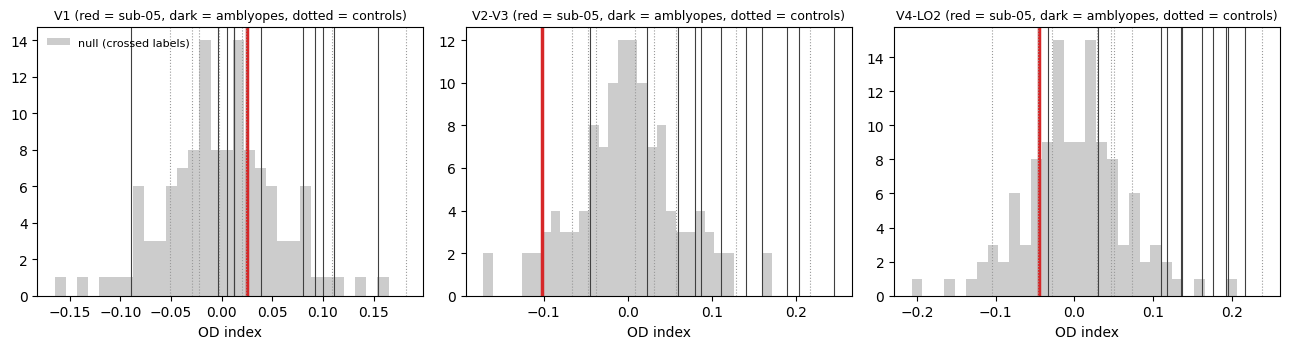

In [7]:
null_rows = []
for s in subj_order:
    R = runs[s]
    for S in itertools.combinations(all_runs, 2):
        notS = [r for r in all_runs if r not in S]
        with np.errstate(divide='ignore', invalid='ignore'):
            tot = R['sxx'][all_runs].sum(0)
            b1 = (R['sxy']['fe'][list(S)].sum(0) + R['sxy']['ae'][notS].sum(0)) / tot
            b2 = (R['sxy']['ae'][list(S)].sum(0) + R['sxy']['fe'][notS].sum(0)) / tot
        for key, rois in roi_sets.items():
            null_rows.append({'subject': s, 'set': key, 'combo': str(S), 'od_null': od_of(R, roi_mask(R, rois), b1, b2)})
null = pd.DataFrame(null_rows)
null_sd = null.groupby('set').od_null.std()
subj_null_sd = null.groupby(['subject', 'set']).od_null.apply(lambda x: np.sqrt(np.mean(x ** 2))).rename('subject_null_rms')
tB = tA[['subject', 'set', 'od_4runs']].merge(subj_null_sd.reset_index(), on=['subject', 'set'])
tB['z_group_null'] = tB.od_4runs / tB.set.map(null_sd)
tB['z_own_null'] = tB.od_4runs / tB.subject_null_rms
print('Null SD per ROI set (all subjects, crossed labels):')
print(null_sd.round(3).to_string())
print()
print(tB[tB.subject == target].set_index('set').round(3).to_string())
compare(tB, 'z_group_null', '\nz (OD / group null SD):')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, key in zip(axes, roi_sets):
    ax.hist(null[null.set == key].od_null.dropna(), bins=30, color='0.8', label='null (crossed labels)')
    d = tB[tB.set == key]
    for s, v in zip(d.subject, d.od_4runs):
        ax.axvline(v, color='tab:red' if s == target else ('0.25' if s in patients else '0.6'),
                   lw=2.5 if s == target else 0.8, ls='-' if s in patients else ':')
    ax.set_title('{} (red = {}, dark = amblyopes, dotted = controls)'.format(key, target), fontsize=9)
    ax.set_xlabel('OD index')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig('{}/sub05_B_null.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()

## C — OD as a function of pRF R²

Vertices binned by their weight (mean pRF R² of the two eyes), OD per bin (weighted median). Also bins of the R² of each eye. If noise produced the reversal, it should be carried by the low-R² vertices and vanish in the best ones. sub-05 (red) vs the other amblyopes (median and 25-75 %).

sub-05: OD and number of vertices per bin of mean pRF R²
set         V1  V2-V3  V4-LO2  V1 (n)  V2-V3 (n)  V4-LO2 (n)
bin                                                         
0.0-0.2  0.020 -0.085  -0.092    2329       3810        3018
0.2-0.4 -0.002 -0.107  -0.068     827       2667        1489
0.4-0.6  0.030 -0.104   0.059    1392       1352         197
0.6-1.0  0.042 -0.087   0.056     119        106          28

Spearman rho, vertex mean R² vs vertex OD index (> 0: the best vertices prefer the fellow eye more):
        sub-05 other amblyopes (median [min, max]) controls (median [min, max])  rank of sub-05 among the 12 amblyopes
set                                                                                                                   
V1       0.113               0.116 [-0.083, 0.393]        0.051 [-0.340, 0.293]                                      6
V2-V3   -0.083               0.233 [-0.085, 0.504]        0.043 [-0.254, 0.373]                                      2

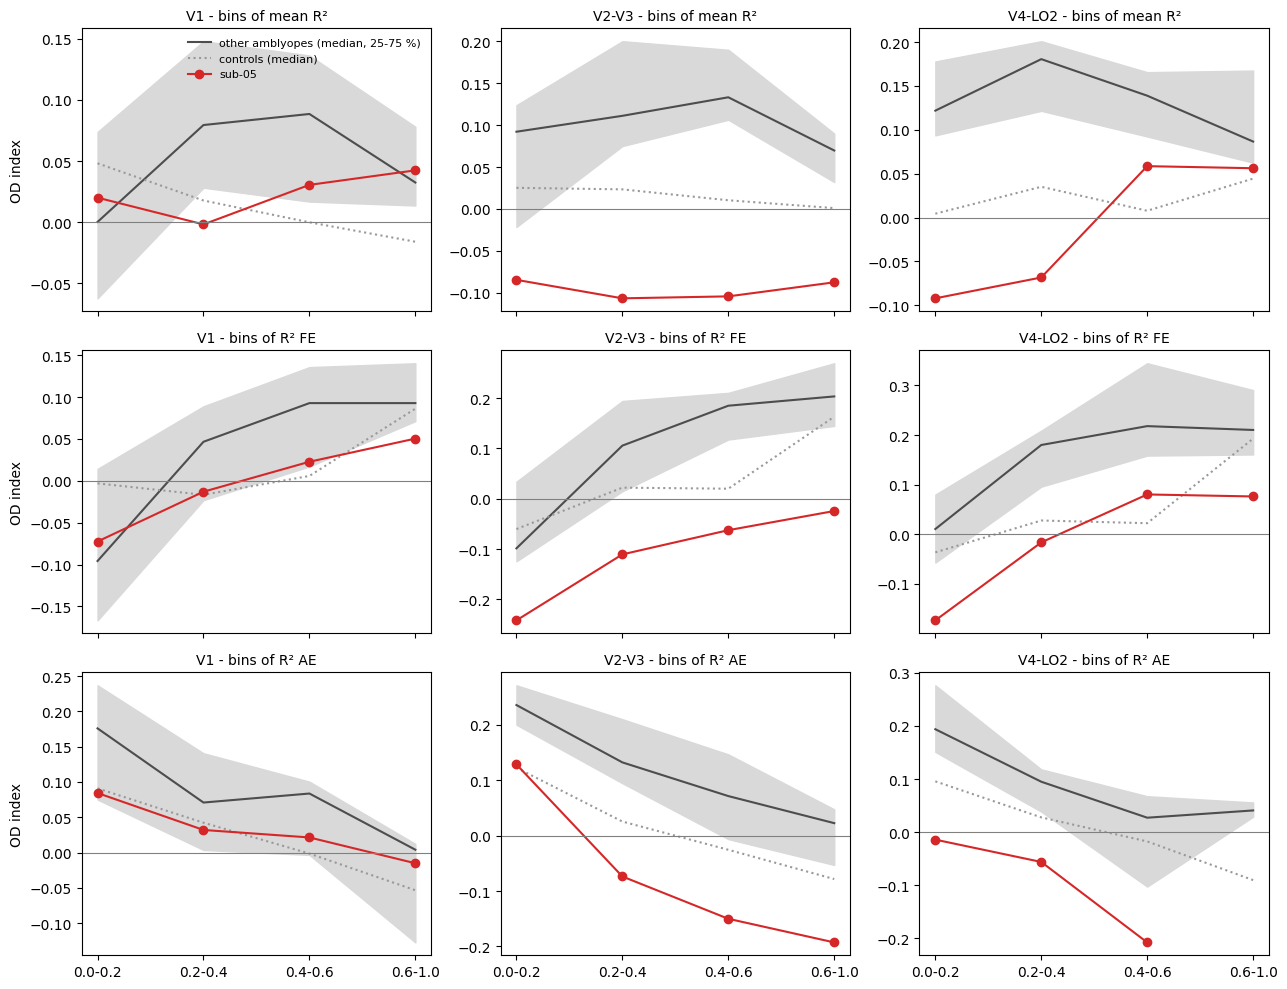

In [8]:
r2_edges = [0, 0.2, 0.4, 0.6, 1.01]
r2_labels = ['{:.1f}-{:.1f}'.format(a, min(b, 1)) for a, b in zip(r2_edges[:-1], r2_edges[1:])]
rows = []
for s in subj_order:
    R = runs[s]
    b_fe, b_ae = beta(R, 'fe', all_runs), beta(R, 'ae', all_runs)
    for key, rois in roi_sets.items():
        for kind, val in [('mean R²', R['w']), ('R² FE', R['rsq']['fe']), ('R² AE', R['rsq']['ae'])]:
            for lab, lo, hi in zip(r2_labels, r2_edges[:-1], r2_edges[1:]):
                m = roi_mask(R, rois, (val >= lo) & (val < hi))
                rows.append({'subject': s, 'set': key, 'kind': kind, 'bin': lab, 'n': m.sum(), 'od': od_of(R, m, b_fe, b_ae)})
tC = pd.DataFrame(rows)
print('{}: OD and number of vertices per bin of mean pRF R²'.format(target))
t = tC[(tC.subject == target) & (tC.kind == 'mean R²')]
print(t.pivot(index='bin', columns='set', values='od').round(3).join(t.pivot(index='bin', columns='set', values='n'), rsuffix=' (n)').to_string())

# Within-subject correlation vertex R² vs vertex OD index (sub-05 and all amblyopes)
rows = []
for s in subj_order:
    R = runs[s]
    odv = od_index(beta(R, 'fe', all_runs), beta(R, 'ae', all_runs))
    for key, rois in roi_sets.items():
        m = roi_mask(R, rois) & np.isfinite(odv)
        rows.append({'subject': s, 'set': key, 'rho_R2_vs_OD': stats.spearmanr(R['w'][m], odv[m])[0] if m.sum() > 10 else np.nan})
tC2 = pd.DataFrame(rows)
compare(tC2, 'rho_R2_vs_OD', '\nSpearman rho, vertex mean R² vs vertex OD index (> 0: the best vertices prefer the fellow eye more):')

fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharex=True)
for i, kind in enumerate(['mean R²', 'R² FE', 'R² AE']):
    for j, key in enumerate(roi_sets):
        ax = axes[i, j]
        d = tC[(tC.kind == kind) & (tC.set == key)]
        po = d[d.subject.isin(others_pat)].groupby('bin').od
        x = np.arange(len(r2_labels))
        ax.fill_between(x, po.quantile(0.25).reindex(r2_labels), po.quantile(0.75).reindex(r2_labels), color='0.85')
        ax.plot(x, po.median().reindex(r2_labels), color='0.3', label='other amblyopes (median, 25-75 %)')
        dc = d[d.subject.isin(controls)].groupby('bin').od.median().reindex(r2_labels)
        ax.plot(x, dc, color='0.6', ls=':', label='controls (median)')
        ax.plot(x, d[d.subject == target].set_index('bin').od.reindex(r2_labels), 'o-', color='tab:red', label=target)
        ax.axhline(0, color='grey', lw=0.8)
        ax.set_title('{} - bins of {}'.format(key, kind), fontsize=10)
        ax.set_xticks(x); ax.set_xticklabels(r2_labels)
        if j == 0: ax.set_ylabel('OD index')
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig('{}/sub05_C_od_vs_r2.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()

## D — OD as a function of eccentricity

Same as C with bins of pRF eccentricity (mean of both eyes). Descriptive: in strabismic amblyopia the suppression of the deviating eye is often central (foveal).

set       V1  V2-V3  V4-LO2  V1 (n)  V2-V3 (n)  V4-LO2 (n)
bin                                                       
0-1°   0.009 -0.201  -0.181     816       1866        1206
1-2°   0.026 -0.160  -0.060     828       1821        1355
2-4°   0.036 -0.047  -0.019    1252       2117        1259
4-8°   0.001  0.067   0.030    1371       1631         659
8-20°  0.137  0.167   0.102     397        497         253


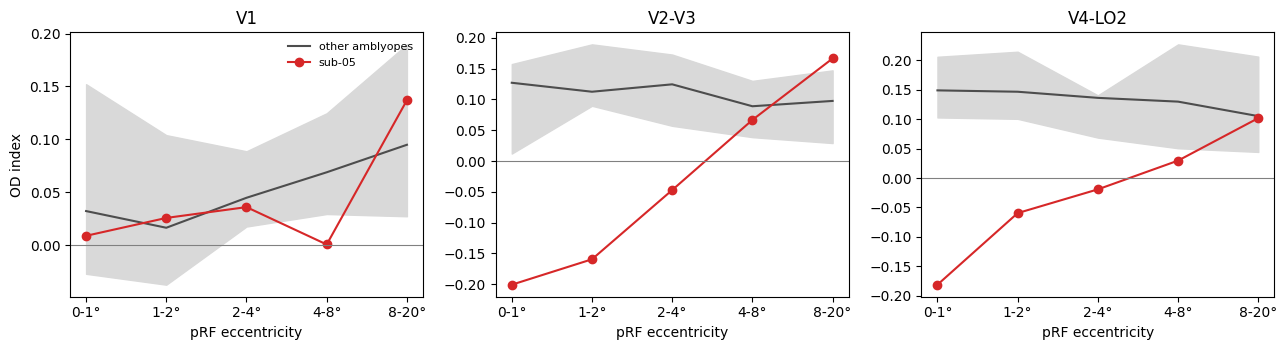

In [9]:
ecc_edges = [0, 1, 2, 4, 8, 20]
ecc_labels = ['{}-{}°'.format(a, b) for a, b in zip(ecc_edges[:-1], ecc_edges[1:])]
rows = []
for s in subj_order:
    R = runs[s]
    b_fe, b_ae = beta(R, 'fe', all_runs), beta(R, 'ae', all_runs)
    ecc = (R['ecc']['fe'] + R['ecc']['ae']) / 2
    for key, rois in roi_sets.items():
        for lab, lo, hi in zip(ecc_labels, ecc_edges[:-1], ecc_edges[1:]):
            m = roi_mask(R, rois, (ecc >= lo) & (ecc < hi))
            rows.append({'subject': s, 'set': key, 'bin': lab, 'n': m.sum(), 'od': od_of(R, m, b_fe, b_ae)})
tD = pd.DataFrame(rows)
t = tD[tD.subject == target]
print(t.pivot(index='bin', columns='set', values='od').reindex(ecc_labels).round(3).join(
    t.pivot(index='bin', columns='set', values='n').reindex(ecc_labels), rsuffix=' (n)').to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, key in zip(axes, roi_sets):
    d = tD[tD.set == key]
    po = d[d.subject.isin(others_pat)].groupby('bin').od
    x = np.arange(len(ecc_labels))
    ax.fill_between(x, po.quantile(0.25).reindex(ecc_labels), po.quantile(0.75).reindex(ecc_labels), color='0.85')
    ax.plot(x, po.median().reindex(ecc_labels), color='0.3', label='other amblyopes')
    ax.plot(x, d[d.subject == target].set_index('bin').od.reindex(ecc_labels), 'o-', color='tab:red', label=target)
    ax.axhline(0, color='grey', lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(ecc_labels); ax.set_title(key); ax.set_xlabel('pRF eccentricity')
axes[0].set_ylabel('OD index'); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig('{}/sub05_D_od_vs_ecc.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()

## E — is it driven by one run?

OD recomputed (i) without each stimulus (both eyes), (ii) without the AE Bars01 run only (R² 0.05 in sub-05), (iii) with each stimulus alone (1 run per eye).

In [10]:
rows = []
for s in subj_order:
    R = runs[s]
    for key, rois in roi_sets.items():
        m = roi_mask(R, rois)
        row = {'subject': s, 'set': key, 'all': od_of(R, m, beta(R, 'fe', all_runs), beta(R, 'ae', all_runs))}
        for k, n in enumerate(run_names):
            keep_r = [r for r in all_runs if r != k]
            row['without {}'.format(n)] = od_of(R, m, beta(R, 'fe', keep_r), beta(R, 'ae', keep_r))
            row['{} alone'.format(n)] = od_of(R, m, beta(R, 'fe', [k]), beta(R, 'ae', [k]))
        row['without AE Bars01'] = od_of(R, m, beta(R, 'fe', all_runs), beta(R, 'ae', [1, 2, 3]))
        rows.append(row)
tE = pd.DataFrame(rows)
cols_wo = ['all'] + ['without {}'.format(n) for n in run_names] + ['without AE Bars01']
cols_al = ['{} alone'.format(n) for n in run_names]
print('{}: leave-out'.format(target))
print(tE[tE.subject == target].set_index('set')[cols_wo].round(3).to_string())
print('\n{}: one stimulus at a time'.format(target))
print(tE[tE.subject == target].set_index('set')[cols_al].round(3).to_string())

sub-05: leave-out
          all  without Bars01  without Bars02  without Rings  without Wedges  without AE Bars01
set                                                                                            
V1      0.025          -0.048           0.065          0.045           0.046             -0.086
V2-V3  -0.102          -0.184          -0.074         -0.070          -0.072             -0.198
V4-LO2 -0.046          -0.134          -0.003         -0.041          -0.004             -0.135

sub-05: one stimulus at a time
        Bars01 alone  Bars02 alone  Rings alone  Wedges alone
set                                                          
V1             0.464        -0.111       -0.036        -0.023
V2-V3          0.331        -0.193       -0.183        -0.182
V4-LO2         0.318        -0.156       -0.093        -0.157


## F — session order (amblyopic eye scanned first in sub-05)

The two eyes were scanned in two blocks of 4 runs. If the signal decreases over the session (fatigue, drowsiness, drift, heating), the eye scanned first gets larger β, whatever the dominance. In sub-05 the **amblyopic** (right) eye was scanned first.

- **Controls** (no dominance expected on average): ratio β(eye scanned first) / β(eye scanned second), V1-V3 → size of the order effect.
- **Amblyopes**: FE first vs AE first.
- **Within-block drift**: per-run β (V1-V3) against its acquisition position (series numbers in `sourcedata/*/<initials>/bids_mapping_verification.txt`, read only).

Ratio eye scanned first / eye scanned second (V1-V3, median over runs)
subject   group  beta_first/second  r2_first/second first_block
 sub-01 patient              1.094            1.041       FE-LE
 sub-02 patient              1.160            1.073       FE-LE
 sub-03 patient              0.713            0.713       AE-RE
 sub-04 patient              0.861            0.904       FE-LE
 sub-05 patient              1.321            1.267       AE-RE
 sub-06 patient              0.848            0.948       AE-RE
 sub-07 patient              0.810            0.962       AE-RE
 sub-08 patient              1.425            2.344       FE-LE
 sub-09 patient              0.702            0.800       AE-RE
 sub-10 patient              1.070            1.129       AE-RE
 sub-11 patient              1.032            0.738       AE-RE
 sub-12 patient              0.783            1.107       AE-RE
 sub-13 control              0.853            0.739       FE-LE
 sub-14 control              0.95

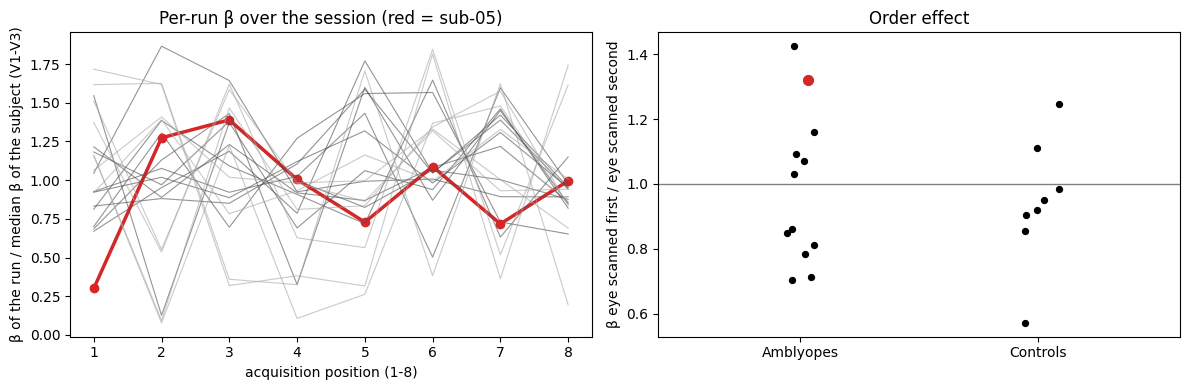

In [11]:
# acquisition position of each run (from the BIDS conversion files of sourcedata)
sub_to_init = {v: k for k, v in initials_to_sub.items()}


def acq_positions(subject):
    init = sub_to_init.get(subject)
    fns = glob.glob('{}/{}/*/{}/bids_mapping_verification.txt'.format(main_dir, project_dir + '/sourcedata', init)) if init else []
    if not fns:
        return None
    pos = {}
    with open(fns[0]) as f:
        for line in f:
            p = line.split()
            if len(p) >= 4 and p[0].isdigit() and p[3].startswith('task-'):
                pos[p[3]] = (int(p[1]), int(p[0]))                 # series number, rank in the table
    order = sorted(pos, key=lambda k: pos[k][0])
    return {k: i + 1 for i, k in enumerate(order)}


def run_task_name(eye_lr, k):
    stim = {'Bars01': ('Bars', '01'), 'Bars02': ('Bars', '02'), 'Rings': ('Rings', '01'), 'Wedges': ('Wedges', '01')}[run_names[k]]
    return 'task-{}{}Eye_run-{}_bold'.format(stim[0], 'Left' if eye_lr == 'L' else 'Right', stim[1])


rows = []
for s in subj_order:
    R = runs[s]
    m = roi_mask(R, early)
    pos = acq_positions(s)
    ae_lr = 'L' if R['fe'] == 'R' else 'R'
    for eye, lr in [('fe', R['fe']), ('ae', ae_lr)]:
        for k in all_runs:
            rows.append({'subject': s, 'group': R['group'], 'eye': eye, 'eye_lr': lr, 'run': run_names[k],
                         'position': pos.get(run_task_name(lr, k), np.nan) if pos else np.nan,
                         'beta': wmedian(beta(R, eye, [k])[m], R['w'][m]),
                         'r2_run': wmedian(R['r2_run'][eye][k][m], R['w'][m])})
tF = pd.DataFrame(rows)
tF['first_eye'] = tF.subject.map(first_eye)
tF['scanned_first'] = tF.eye_lr == tF.first_eye

# Order effect: ratio first / second block
ratio = tF.groupby(['subject', 'group', 'scanned_first']).agg(beta=('beta', 'median'), r2=('r2_run', 'median')).unstack('scanned_first')
ratio = pd.DataFrame({'beta_first/second': ratio[('beta', True)] / ratio[('beta', False)],
                      'r2_first/second': ratio[('r2', True)] / ratio[('r2', False)]}).reset_index()
fe_first = {s: first_eye.get(s) == runs[s]['fe'] for s in subj_order}
ratio['first_block'] = ['FE-LE' if fe_first[s] else 'AE-RE' for s in ratio.subject]
print('Ratio eye scanned first / eye scanned second (V1-V3, median over runs)')
print(ratio.round(3).to_string(index=False))
rc = ratio[ratio.group == 'control']
print('\nControls: beta ratio first/second median {:.3f} [{:.3f}, {:.3f}], Wilcoxon vs 1 p = {:.3f}; R² ratio median {:.3f}, p = {:.3f}'.format(
    rc['beta_first/second'].median(), rc['beta_first/second'].min(), rc['beta_first/second'].max(),
    stats.wilcoxon(np.log(rc['beta_first/second'])).pvalue, rc['r2_first/second'].median(), stats.wilcoxon(np.log(rc['r2_first/second'])).pvalue))
r5 = ratio[ratio.subject == target].iloc[0]
print('{}: AE scanned first, beta ratio first/second = {:.3f} (= AE/FE), R² ratio = {:.3f}'.format(target, r5['beta_first/second'], r5['r2_first/second']))
print('-> if the controls show a first-block advantage of this size, the order alone could explain the AE advantage of {}.'.format(target))

# Within-block drift: slope of log beta over the position within the block
rows = []
for (s, eye), d in tF.dropna(subset=['position']).groupby(['subject', 'eye']):
    d = d.sort_values('position')
    if len(d) >= 3 and (d.beta > 0).all():
        rows.append({'subject': s, 'eye': eye, 'slope_log_beta_per_run': np.polyfit(d.position - d.position.min(), np.log(d.beta), 1)[0]})
drift = pd.DataFrame(rows)
print('\nWithin-block drift, slope of log β per run (median across subjects and eyes): {:.3f}; {}: {}'.format(
    drift.slope_log_beta_per_run.median(), target,
    drift[drift.subject == target].set_index('eye').slope_log_beta_per_run.round(3).to_dict()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s in subj_order:
    d = tF[tF.subject == s].dropna(subset=['position']).sort_values('position')
    if not len(d):
        continue
    col = 'tab:red' if s == target else ('0.3' if s in patients else '0.65')
    axes[0].plot(d.position, d.beta / d.beta.median(), 'o-' if s == target else '-', color=col, lw=2.5 if s == target else 0.8, alpha=1 if s == target else 0.6)
axes[0].set_xlabel('acquisition position (1-8)'); axes[0].set_ylabel('β of the run / median β of the subject (V1-V3)')
axes[0].set_title('Per-run β over the session (red = {})'.format(target))
for g_i, g in enumerate(groups):
    d = ratio[ratio.group == g]
    for s, v in zip(d.subject, d['beta_first/second']):
        axes[1].scatter(g_i + np.random.default_rng(hash(s) % 100).uniform(-0.1, 0.1), v,
                        color='tab:red' if s == target else 'black', s=50 if s == target else 18)
axes[1].axhline(1, color='grey', lw=1)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels([group_labels[g] for g in groups]); axes[1].set_xlim(-0.6, 1.6)
axes[1].set_ylabel('β eye scanned first / eye scanned second'); axes[1].set_title('Order effect')
plt.tight_layout(); fig.savefig('{}/sub05_F_session_order.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()

## G — head motion per run

Mean framewise displacement (fMRIPrep confounds, read only) of each run, FE vs AE.

In [12]:
rows = []
for s in subj_order:
    fns = glob.glob('{}/{}/derivatives/fmriprep/fmriprep/{}/ses-*/func/{}_*task-*Eye*desc-confounds_timeseries.tsv'.format(main_dir, project_dir, s, s))
    for fn in fns:
        name = os.path.basename(fn)
        try:
            fd = pd.read_csv(fn, sep='\t', usecols=['framewise_displacement']).framewise_displacement
        except Exception:
            continue
        eye_lr = 'L' if 'LeftEye' in name else 'R'
        rows.append({'subject': s, 'group': runs[s]['group'], 'run': name.split('_task-')[1].split('_desc')[0],
                     'eye': 'FE-LE' if eye_lr == runs[s]['fe'] else 'AE-RE', 'fd_mean': fd.mean(), 'fd_pct_above_0.5': 100 * np.mean(fd > 0.5)})
tG = pd.DataFrame(rows)
if len(tG):
    print('{}: framewise displacement per run'.format(target))
    print(tG[tG.subject == target].sort_values('eye').round(3).to_string(index=False))
    fdr = tG.groupby(['subject', 'group', 'eye']).fd_mean.mean().unstack('eye')
    fdr['AE/FE'] = fdr['AE-RE'] / fdr['FE-LE']
    print('\nMean FD per eye and ratio AE/FE (all subjects):')
    print(fdr.round(3).to_string())
else:
    print('No fMRIPrep confounds found under derivatives/fmriprep: adapt the path.')

sub-05: framewise displacement per run
subject   group                   run   eye  fd_mean  fd_pct_above_0.5
 sub-05 patient   BarsRightEye_run-01 AE-RE    0.110               0.0
 sub-05 patient   BarsRightEye_run-02 AE-RE    0.096               0.0
 sub-05 patient  RingsRightEye_run-01 AE-RE    0.108               0.0
 sub-05 patient WedgesRightEye_run-01 AE-RE    0.098               0.0
 sub-05 patient  WedgesLeftEye_run-01 FE-LE    0.094               0.0
 sub-05 patient   RingsLeftEye_run-01 FE-LE    0.113               0.0
 sub-05 patient    BarsLeftEye_run-01 FE-LE    0.101               0.0
 sub-05 patient    BarsLeftEye_run-02 FE-LE    0.101               0.0

Mean FD per eye and ratio AE/FE (all subjects):
eye              AE-RE  FE-LE  AE/FE
subject group                       
sub-01  patient  0.100  0.098  1.024
sub-02  patient  0.070  0.075  0.932
sub-03  patient  0.165  0.150  1.097
sub-04  patient  0.227  0.193  1.178
sub-05  patient  0.103  0.102  1.005
sub-06  patien

## H — pRFs of each eye

Per ROI set: median pRF R², eccentricity and size of each eye (selected vertices, weighted), and number of vertices passing the prf_analysis filters for each eye alone (v9 selection). Is sub-05's amblyopic eye unusually good, or its fellow eye unusually poor?

In [13]:
rows = []
for s in subj_order:
    R = runs[s]
    sd = load_subject(s)
    vd = vertex_data[s]
    ae = 'L' if vd['fe'] == 'R' else 'R'
    for key, rois in roi_sets.items():
        m = roi_mask(R, rois)
        in_roi = np.any([sd['rois'][r] for r in rois], axis=0)
        sel = {e: select(sd['d'][e], sd['p'][e]) & in_roi for e in ['L', 'R']}
        row = {'subject': s, 'set': key, 'n_sel_FE': sel[vd['fe']].sum(), 'n_sel_AE': sel[ae].sum()}
        row['n_sel_AE/FE'] = row['n_sel_AE'] / max(row['n_sel_FE'], 1)
        for q in ['rsq', 'ecc', 'size']:
            for eye in ['fe', 'ae']:
                row['{}_{}'.format(q, eye.upper())] = wmedian(R[q][eye][m], R['w'][m])
            row['{}_AE/FE'.format(q)] = row['{}_AE'.format(q)] / row['{}_FE'.format(q)]
        rows.append(row)
tH = pd.DataFrame(rows)
print('{}:'.format(target))
print(tH[tH.subject == target].set_index('set').drop(columns='subject').round(3).T.to_string())
for v in ['rsq_AE/FE', 'n_sel_AE/FE', 'size_AE/FE', 'ecc_AE/FE']:
    compare(tH, v, '\n{}:'.format(v))

sub-05:
set                V1     V2-V3    V4-LO2
n_sel_FE     5912.000  9729.000  5380.000
n_sel_AE     5910.000  9689.000  5591.000
n_sel_AE/FE     1.000     0.996     1.039
rsq_FE          0.508     0.347     0.223
rsq_AE          0.437     0.385     0.260
rsq_AE/FE       0.859     1.108     1.163
ecc_FE          2.385     1.885     1.993
ecc_AE          2.199     1.541     1.514
ecc_AE/FE       0.922     0.818     0.759
size_FE         0.329     0.408     0.715
size_AE         0.504     0.587     0.540
size_AE/FE      1.533     1.439     0.756

rsq_AE/FE:
        sub-05 other amblyopes (median [min, max]) controls (median [min, max])  rank of sub-05 among the 12 amblyopes
set                                                                                                                   
V1       0.859                0.920 [0.575, 1.137]         0.922 [0.566, 1.202]                                      4
V2-V3    1.108                0.828 [0.435, 1.068]         0.912 [0.533, 1.34

## Summary

In [14]:
summ = []
for key in roi_sets:
    a = tA[(tA.subject == target) & (tA.set == key)].iloc[0]
    b = tB[(tB.subject == target) & (tB.set == key)].iloc[0]
    e = tE[(tE.subject == target) & (tE.set == key)].iloc[0]
    c = tC[(tC.subject == target) & (tC.set == key) & (tC.kind == 'mean R²')].set_index('bin').od
    summ.append({'set': key, 'OD 4 runs': a.od_4runs, 'halves with same sign': a.halves_same_sign_as_4runs,
                 'z vs noise': b.z_group_null, 'OD lowest R² bin': c.iloc[0], 'OD highest R² bin': c.dropna().iloc[-1],
                 'OD range leave-one-stimulus-out': '{:.3f} to {:.3f}'.format(e[['without {}'.format(n) for n in run_names]].min(),
                                                                            e[['without {}'.format(n) for n in run_names]].max()),
                 'OD without AE Bars01': e['without AE Bars01']})
print(pd.DataFrame(summ).set_index('set').round(3).to_string())

        OD 4 runs halves with same sign  z vs noise  OD lowest R² bin  OD highest R² bin OD range leave-one-stimulus-out  OD without AE Bars01
set                                                                                                                                           
V1          0.025                   3/6       0.457             0.020              0.042                 -0.048 to 0.065                -0.086
V2-V3      -0.102                   4/6      -1.648            -0.085             -0.087                -0.184 to -0.070                -0.198
V4-LO2     -0.046                   3/6      -0.705            -0.092              0.056                -0.134 to -0.003                -0.135


## Reading guide

- **Real effect** (not explained by bad signal): same sign in the 6 halves, |z| > 2 vs the crossed-label noise, reversal present (or stronger) in the high-R² vertices, stable when any run is removed, no fellow-eye disadvantage in motion, and an order effect in the controls much smaller than sub-05's AE/FE ratio.
- **Order artefact**: controls with a first-block advantage of the size of sub-05's AE/FE β ratio, and a decreasing β over the session.
- **Noise**: OD within the null spread, sign changing between halves, reversal limited to low-R² vertices.
- Whatever the outcome, sub-05 stays in the group analyses (no a priori reason to exclude); this notebook documents it as an atypical subject.